In [1]:
K = 5
L = 0
g = 3
HOP = 2048

In [2]:
"""HNMA / regularized non-negative matrix factorization.

Factorization:
    X ~= W @ H

X: (frequency_bins, frames)
W: (frequency_bins, components)
H: (components, frames)

In the paper's notation W corresponds to A and H to S.

Regularizers
------------
alpha(W or H):
    lambda_alpha * sum(Z**p)

beta(H):
    beta1 / 'sparsity':
        mu * sum(H**p)

    beta2 / 'cross_correlation':
        mu * sum(H * (C @ H))

    beta3 / 'temporal_smoothness':
        -mu * sum((H @ V) * H)

For beta3, beta3_exponential=True replaces beta3 by exp(beta3).

The basis shift-similarity term from the earlier implementation
is retained.

Dependencies: NumPy only.
"""

from __future__ import annotations

from typing import Optional, Literal, Union, Mapping, Sequence
import warnings
import numpy as np
np.random.seed(42)
ArrayLike = Union[np.ndarray, list]


class HNMA:
    """Regularized non-negative matrix factorization."""

    def __init__(
        self,
        n_components: Optional[int] = None,

        # Alpha: generalized sparsity.
        lambda_alpha: float = 0.0,
        alpha_target: Literal['H', 'W'] = 'H',
        alpha_measure: Literal['l1', 'l2', 'lp', 'none'] = 'l1',
        alpha_power: float = 1.0,

        # Beta: additional regularization.
        beta_mode: Literal[
            'none',
            'sparsity',
            'cross_correlation',
            'temporal_smoothness',
            'beta1',
            'beta2',
            'beta3'
        ] = 'none',

        lambda_beta: float = 0.0,
        beta_power: float = 1.0,

        beta_weights: Optional[ArrayLike] = None,
        beta_interval_weights: Optional[Mapping[int, float]] = None,
        pitch_numbers: Optional[Sequence[int]] = None,

        temporal_weights: Optional[ArrayLike] = None,
        temporal_lags: Optional[Mapping[int, float]] = None,
        temporal_circular: bool = False,
        beta3_exponential: bool = False,

        # Legacy options.
        lambda_h: float = 0.0,
        lambda_shift: float = 0.0,

        sparsity_measure: Literal[
            'l1', 'none', 'l2', 'lp'
        ] = 'l1',

        sparsity_power: float = 1.0,

        bins_per_octave: int = 36,
        shift_bins: Optional[int] = None,

        normalize_W: bool = True,

        max_iter: int = 300,
        tol: float = 1e-5,
        min_iter: int = 10,
        patience: int = 5,
        epsilon: float = 1e-10,

        random_state: Optional[int] = None,
        verbose: bool = False,
        eval_every: int = 1,
    ):

        if n_components is not None and n_components <= 0:
            raise ValueError(
                'n_components must be positive or None.'
            )

        for name, value in (
            ('lambda_alpha', lambda_alpha),
            ('lambda_beta', lambda_beta),
            ('lambda_h', lambda_h),
            ('lambda_shift', lambda_shift),
        ):
            if value < 0:
                raise ValueError(
                    f'{name} must be non-negative.'
                )

        if alpha_target not in {'H', 'W'}:
            raise ValueError(
                "alpha_target must be 'H' or 'W'."
            )

        if alpha_measure not in {
            'l1', 'l2', 'lp', 'none'
        }:
            raise ValueError(
                "alpha_measure must be 'l1', 'l2', 'lp', or 'none'."
            )

        if alpha_power <= 0:
            raise ValueError(
                'alpha_power must be positive.'
            )

        if sparsity_measure not in {
            'l1', 'l2', 'lp', 'none'
        }:
            raise ValueError(
                "sparsity_measure must be 'l1', 'l2', 'lp', or 'none'."
            )

        if sparsity_power <= 0:
            raise ValueError(
                'sparsity_power must be positive.'
            )

        if beta_power <= 0:
            raise ValueError(
                'beta_power must be positive.'
            )

        beta_aliases = {
            'beta1': 'sparsity',
            'beta2': 'cross_correlation',
            'beta3': 'temporal_smoothness',
            'smoothness': 'temporal_smoothness',
            'cross-correlation': 'cross_correlation',
            'temporal': 'temporal_smoothness',
        }

        beta_mode = beta_aliases.get(
            beta_mode, beta_mode
        )

        if beta_mode not in {
            'none',
            'sparsity',
            'cross_correlation',
            'temporal_smoothness'
        }:
            raise ValueError(
                "beta_mode must be 'none', 'sparsity'/'beta1', "
                "'cross_correlation'/'beta2', or "
                "'temporal_smoothness'/'beta3'."
            )

        if sparsity_measure == 'none':
            lambda_h = 0.0

        if alpha_measure == 'none':
            lambda_alpha = 0.0

        if bins_per_octave <= 0:
            raise ValueError(
                'bins_per_octave must be positive.'
            )

        if shift_bins is None:
            if bins_per_octave % 12 != 0:
                raise ValueError(
                    'bins_per_octave must be divisible by 12, '
                    'or set shift_bins explicitly.'
                )

            shift_bins = bins_per_octave // 12

        if shift_bins <= 0:
            raise ValueError(
                'shift_bins must be positive.'
            )

        if (
            max_iter <= 0
            or min_iter < 0
            or patience <= 0
            or eval_every <= 0
        ):
            raise ValueError(
                'Invalid iteration/convergence settings.'
            )

        if tol < 0 or epsilon <= 0:
            raise ValueError(
                'tol must be nonnegative and epsilon positive.'
            )

        if (
            beta_weights is not None
            and beta_interval_weights is not None
        ):
            raise ValueError(
                'Specify beta_weights or beta_interval_weights, not both.'
            )

        if (
            temporal_weights is not None
            and temporal_lags is not None
        ):
            raise ValueError(
                'Specify temporal_weights or temporal_lags, not both.'
            )

        if (
            beta_mode == 'temporal_smoothness'
            and lambda_beta
            and not beta3_exponential
        ):
            warnings.warn(
                'Raw beta3 is a negative quadratic regularizer and '
                'can make the objective unbounded below for sufficiently '
                'large lambda_beta. Consider beta3_exponential=True '
                'and validate the result.',
                RuntimeWarning,
            )

        # Store parameters.

        self.n_components = n_components

        self.lambda_alpha = float(lambda_alpha)
        self.alpha_target = alpha_target
        self.alpha_measure = alpha_measure
        self.alpha_power = float(alpha_power)

        self.beta_mode = beta_mode
        self.lambda_beta = float(lambda_beta)
        self.beta_power = float(beta_power)

        self.beta_weights = (
            None if beta_weights is None
            else np.asarray(beta_weights, dtype=np.float64)
        )

        self.beta_interval_weights = (
            None if beta_interval_weights is None
            else dict(beta_interval_weights)
        )

        self.pitch_numbers = (
            None if pitch_numbers is None
            else np.asarray(pitch_numbers, dtype=int)
        )

        self.temporal_weights = (
            None if temporal_weights is None
            else np.asarray(temporal_weights, dtype=np.float64)
        )

        self.temporal_lags = (
            {1: 1.0} if temporal_lags is None
            else dict(temporal_lags)
        )

        self.temporal_circular = bool(temporal_circular)
        self.beta3_exponential = bool(beta3_exponential)

        # Legacy options.

        self.lambda_h = float(lambda_h)
        self.lambda_shift = float(lambda_shift)

        self.sparsity_measure = sparsity_measure
        self.sparsity_power = float(sparsity_power)

        self.bins_per_octave = int(bins_per_octave)
        self.shift_bins = int(shift_bins)

        self.normalize_W = bool(normalize_W)

        self.max_iter = int(max_iter)
        self.tol = float(tol)
        self.min_iter = int(min_iter)
        self.patience = int(patience)
        self.epsilon = float(epsilon)

        self.random_state = random_state
        self.verbose = bool(verbose)
        self.eval_every = int(eval_every)

        # Fitted attributes.

        self.components_ = None
        self.activations_ = None
        self.reconstruction_ = None

        self.objective_history_ = []
        self.alpha_history_ = []
        self.beta_history_ = []

        self.n_iter_ = 0
        self.n_features_in_ = None
        self.n_frames_in_ = None
        self.converged_ = False

        self.cross_correlation_weights_ = None
        self.temporal_weights_ = None

        if (
            self.lambda_alpha > 0
            and self.alpha_target == 'W'
            and self.alpha_measure == 'l1'
            and self.normalize_W
        ):
            warnings.warn(
                "alpha_target='W' with L1 sparsity and normalize_W=True "
                "is a constant penalty (each W column sums to one). "
                "Use alpha_power between 0 and 1 with "
                "alpha_measure='lp', or disable normalization.",
                RuntimeWarning,
            )

    # ---------------------------------------------------------
    # Validation and initialization
    # ---------------------------------------------------------

    def _validate_X(self, X: ArrayLike) -> np.ndarray:

        X = np.asarray(X, dtype=np.float64)

        if X.ndim != 2 or min(X.shape) == 0:
            raise ValueError(
                'X must be a non-empty 2D (frequency, time) matrix.'
            )

        if not np.all(np.isfinite(X)):
            raise ValueError(
                'X contains NaN or infinite values.'
            )

        if np.any(X < 0):
            raise ValueError(
                'NMF requires X >= 0.'
            )

        return X

    def _infer_rank(self, W_init, H_init):

        inferred = []

        if W_init is not None:
            w = np.asarray(W_init)

            if w.ndim != 2:
                raise ValueError(
                    'W_init must be 2D (frequency, components).'
                )

            inferred.append(w.shape[1])

        if H_init is not None:
            h = np.asarray(H_init)

            if h.ndim != 2:
                raise ValueError(
                    'H_init must be 2D (components, time).'
                )

            inferred.append(h.shape[0])

        if inferred and any(k != inferred[0] for k in inferred):
            raise ValueError(
                'W_init and H_init disagree on the component count.'
            )

        if (
            self.n_components is not None
            and inferred
            and self.n_components != inferred[0]
        ):
            raise ValueError(
                'n_components does not match W_init/H_init.'
            )

        if self.n_components is not None:
            return int(self.n_components)

        if inferred:
            return int(inferred[0])

        raise ValueError(
            'Set n_components or provide W_init/H_init.'
        )

    def _normalize_columns(self, W, H=None):

        sums = np.maximum(
            np.sum(W, axis=0),
            self.epsilon
        )

        W /= sums[None, :]

        if H is not None:
            H *= sums[:, None]

        return W, H

    def _initialize(self, X, W_init, H_init):

        F, T = X.shape
        K = self._infer_rank(W_init, H_init)

        rng = np.random.default_rng(self.random_state)

        if W_init is not None:

            W = np.asarray(
                W_init, dtype=np.float64
            ).copy()

            if (
                W.shape != (F, K)
                or not np.all(np.isfinite(W))
                or np.any(W < 0)
            ):
                raise ValueError(
                    f'W_init must be finite, nonnegative, '
                    f'and shaped {(F, K)}.'
                )

            W = np.maximum(W, self.epsilon)

        else:
            W = rng.random((F, K)) + 0.1

        if H_init is not None:

            H = np.asarray(
                H_init, dtype=np.float64
            ).copy()

            if (
                H.shape != (K, T)
                or not np.all(np.isfinite(H))
                or np.any(H < 0)
            ):
                raise ValueError(
                    f'H_init must be finite, nonnegative, '
                    f'and shaped {(K, T)}.'
                )

            H = np.maximum(H, self.epsilon)

        else:
            H = None

        if self.normalize_W:
            W, H = self._normalize_columns(W, H)

        if H is None:

            H = np.maximum(
                W.T @ X,
                self.epsilon
            )

            H *= (
                (W.T @ X + self.epsilon)
                / (W.T @ W @ H + self.epsilon)
            )

            H = np.maximum(H, self.epsilon)

        return W, H

    # ---------------------------------------------------------
    # Basis shift-similarity regularization
    # ---------------------------------------------------------

    def _shifted_down_right(self, W):

        q = self.shift_bins

        shifted = np.zeros_like(W)

        if q < W.shape[0] and W.shape[1] > 1:
            shifted[q:, 1:] = W[:-q, :-1]

        return shifted

    def _shift_gradient(self, W):

        if self.lambda_shift == 0:
            return np.zeros_like(W)

        D = W - self._shifted_down_right(W)

        adjoint = np.zeros_like(D)

        q = self.shift_bins

        if q < W.shape[0] and W.shape[1] > 1:
            adjoint[:-q, :-1] = D[q:, 1:]

        return 2.0 * self.lambda_shift * (D - adjoint)

    # ---------------------------------------------------------
    # Alpha: generalized sparsity
    # ---------------------------------------------------------

    @staticmethod
    def _power_from_measure(measure, power):

        if measure == 'none':
            return None

        if measure == 'l1':
            return 1.0

        if measure == 'l2':
            return 2.0

        return float(power)

    def _alpha_power(self):

        return self._power_from_measure(
            self.alpha_measure,
            self.alpha_power
        )

    def _legacy_h_power(self):

        return self._power_from_measure(
            self.sparsity_measure,
            self.sparsity_power
        )

    def _alpha_objective(self, W, H):

        p = self._alpha_power()

        if self.lambda_alpha == 0 or p is None:
            return 0.0

        Z = W if self.alpha_target == 'W' else H

        return self.lambda_alpha * float(
            np.sum(np.maximum(Z, 0.0) ** p)
        )

    def _alpha_gradient(self, W, H):

        gW = np.zeros_like(W)
        gH = np.zeros_like(H)

        p = self._alpha_power()

        if self.lambda_alpha == 0 or p is None:
            return gW, gH

        if self.alpha_target == 'W':

            gW = (
                self.lambda_alpha
                * p
                * np.maximum(W, self.epsilon) ** (p - 1.0)
            )

        else:

            gH = (
                self.lambda_alpha
                * p
                * np.maximum(H, self.epsilon) ** (p - 1.0)
            )

        return gW, gH

    # ---------------------------------------------------------
    # Beta: cross-correlation weights
    # ---------------------------------------------------------

    def _build_cross_correlation_weights(self, K):

        if self.beta_weights is not None:

            C = np.asarray(
                self.beta_weights,
                dtype=np.float64
            ).copy()

            if C.shape != (K, K):
                raise ValueError(
                    f'beta_weights must have shape {(K, K)}.'
                )

            if (
                not np.all(np.isfinite(C))
                or np.any(C < 0)
            ):
                raise ValueError(
                    'beta_weights must be finite and nonnegative.'
                )

            C = 0.5 * (C + C.T)

        elif self.beta_interval_weights is not None:

            if self.pitch_numbers is None:
                pitches = np.arange(21, 21 + K)

            else:
                pitches = self.pitch_numbers

                if pitches.shape != (K,):
                    raise ValueError(
                        f'pitch_numbers must contain {K} MIDI pitches.'
                    )

            interval_map = {}

            for key, value in self.beta_interval_weights.items():

                interval = int(key)

                if interval < 0 or interval > 11:
                    raise ValueError(
                        'beta_interval_weights keys must be intervals 0..11.'
                    )

                value = float(value)

                if value < 0 or not np.isfinite(value):
                    raise ValueError(
                        'Interval weights must be finite and nonnegative.'
                    )

                interval_map[interval] = value

            C = np.zeros(
                (K, K),
                dtype=np.float64
            )

            for i in range(K):

                for j in range(i + 1, K):

                    d = int(
                        (pitches[i] - pitches[j]) % 12
                    )

                    w = max(
                        interval_map.get(d, 0.0),
                        interval_map.get((-d) % 12, 0.0)
                    )

                    C[i, j] = C[j, i] = w

        else:

            C = (
                np.ones((K, K), dtype=np.float64)
                - np.eye(K)
            )

        np.fill_diagonal(C, 0.0)

        return C

    # ---------------------------------------------------------
    # Beta: temporal weights
    # ---------------------------------------------------------

    def _build_temporal_weights(self, T):

        V = np.asarray(
            self.temporal_weights,
            dtype=np.float64
        ).copy()

        if V.shape != (T, T):
            raise ValueError(
                f'temporal_weights must have shape {(T, T)}.'
            )

        if (
            not np.all(np.isfinite(V))
            or np.any(V < 0)
        ):
            raise ValueError(
                'temporal_weights must be finite and nonnegative.'
            )

        V = 0.5 * (V + V.T)

        np.fill_diagonal(V, 0.0)

        return V

    def _temporal_beta_and_gradient(self, H):

        if self.temporal_weights_ is not None:

            V = self.temporal_weights_

            if V.shape != (H.shape[1], H.shape[1]):
                raise ValueError(
                    'Stored temporal_weights_ does not match H length.'
                )

            raw = -self.lambda_beta * float(
                np.sum((H @ V) * H)
            )

            grad = -self.lambda_beta * (
                H @ (V + V.T)
            )

            return raw, grad

        T = H.shape[1]

        raw = 0.0
        grad = np.zeros_like(H)

        for lag, weight in self.temporal_lags.items():

            lag = int(lag)
            weight = float(weight)

            if lag <= 0:
                raise ValueError(
                    'temporal_lags must contain positive lags.'
                )

            if weight < 0 or not np.isfinite(weight):
                raise ValueError(
                    'Temporal lag weights must be finite and nonnegative.'
                )

            if lag >= T or weight == 0:
                continue

            # Symmetric V has entries:
            # V[t, t+lag] = V[t+lag, t] = weight.

            left = H[:, :-lag]
            right = H[:, lag:]

            coeff = 2.0 * self.lambda_beta * weight

            raw -= coeff * float(
                np.sum(left * right)
            )

            grad[:, :-lag] -= coeff * right
            grad[:, lag:] -= coeff * left

            if self.temporal_circular:

                left_wrap = H[:, -lag:]
                right_wrap = H[:, :lag]

                raw -= coeff * float(
                    np.sum(left_wrap * right_wrap)
                )

                grad[:, -lag:] -= coeff * right_wrap
                grad[:, :lag] -= coeff * left_wrap

        return raw, grad

    # ---------------------------------------------------------
    # Prepare beta regularization
    # ---------------------------------------------------------

    def _ensure_beta_weights(self, H):

        if self.lambda_beta == 0 or self.beta_mode == 'none':

            self.cross_correlation_weights_ = None
            self.temporal_weights_ = None

        elif self.beta_mode == 'cross_correlation':

            self.cross_correlation_weights_ = (
                self._build_cross_correlation_weights(
                    H.shape[0]
                )
            )

            self.temporal_weights_ = None

        elif self.beta_mode == 'temporal_smoothness':

            self.cross_correlation_weights_ = None

            self.temporal_weights_ = (
                self._build_temporal_weights(H.shape[1])
                if self.temporal_weights is not None
                else None
            )

            for lag, weight in self.temporal_lags.items():

                if (
                    int(lag) <= 0
                    or float(weight) < 0
                    or not np.isfinite(float(weight))
                ):
                    raise ValueError(
                        'temporal_lags must map positive lags '
                        'to finite nonnegative weights.'
                    )

        else:

            self.cross_correlation_weights_ = None
            self.temporal_weights_ = None

    # ---------------------------------------------------------
    # Beta: objective
    # ---------------------------------------------------------

    def _beta_objective(self, H):

        if self.lambda_beta == 0 or self.beta_mode == 'none':
            return 0.0

        if self.beta_mode == 'sparsity':

            return self.lambda_beta * float(
                np.sum(
                    np.maximum(H, 0.0) ** self.beta_power
                )
            )

        if self.beta_mode == 'cross_correlation':

            C = self.cross_correlation_weights_

            if C is None or C.shape != (H.shape[0], H.shape[0]):
                C = self._build_cross_correlation_weights(
                    H.shape[0]
                )

            return self.lambda_beta * float(
                np.sum(H * (C @ H))
            )

        if self.beta_mode == 'temporal_smoothness':

            raw_beta3, _ = self._temporal_beta_and_gradient(H)

            if self.beta3_exponential:

                return float(
                    np.exp(
                        np.clip(raw_beta3, -700.0, 0.0)
                    )
                )

            return raw_beta3

        raise RuntimeError(
            'Unexpected beta_mode.'
        )

    # ---------------------------------------------------------
    # Beta: gradient
    # ---------------------------------------------------------

    def _beta_gradient(self, H):

        if self.lambda_beta == 0 or self.beta_mode == 'none':
            return np.zeros_like(H)

        if self.beta_mode == 'sparsity':

            return (
                self.lambda_beta
                * self.beta_power
                * np.maximum(H, self.epsilon) ** (
                    self.beta_power - 1.0
                )
            )

        if self.beta_mode == 'cross_correlation':

            C = self.cross_correlation_weights_

            if C is None or C.shape != (H.shape[0], H.shape[0]):
                C = self._build_cross_correlation_weights(
                    H.shape[0]
                )

            return self.lambda_beta * (
                (C + C.T) @ H
            )

        if self.beta_mode == 'temporal_smoothness':

            raw_beta3, grad = (
                self._temporal_beta_and_gradient(H)
            )

            if self.beta3_exponential:

                grad *= float(
                    np.exp(
                        np.clip(raw_beta3, -700.0, 0.0)
                    )
                )

            return grad

        raise RuntimeError(
            'Unexpected beta_mode.'
        )

    # ---------------------------------------------------------
    # Objective and multiplicative-update helpers
    # ---------------------------------------------------------

    @staticmethod
    def _positive_part(A):
        return np.maximum(A, 0.0)

    @staticmethod
    def _negative_part(A):
        return np.maximum(-A, 0.0)

    def _regularizer_gradient_W(self, W, H):

        gW, _ = self._alpha_gradient(W, H)

        return gW + self._shift_gradient(W)

    def _regularizer_gradient_H(self, W, H):

        _, gH = self._alpha_gradient(W, H)

        p_legacy = self._legacy_h_power()

        if self.lambda_h and p_legacy is not None:

            gH = (
                gH
                + self.lambda_h
                * p_legacy
                * np.maximum(H, self.epsilon) ** (
                    p_legacy - 1.0
                )
            )

        return gH + self._beta_gradient(H)

    def _objective(self, X, W, H):

        R = X - W @ H

        value = 0.5 * float(
            np.sum(R * R)
        )

        value += self._alpha_objective(W, H)

        p_legacy = self._legacy_h_power()

        if self.lambda_h and p_legacy is not None:

            value += self.lambda_h * float(
                np.sum(
                    np.maximum(H, 0.0) ** p_legacy
                )
            )

        value += self._beta_objective(H)

        if self.lambda_shift:

            D = W - self._shifted_down_right(W)

            value += self.lambda_shift * float(
                np.sum(D * D)
            )

        return value

    # ---------------------------------------------------------
    # Fit
    # ---------------------------------------------------------

    def fit(
        self,
        X,
        *,
        W_init=None,
        H_init=None,
    ):

        X = self._validate_X(X)

        F, T = X.shape

        W, H = self._initialize(
            X,
            W_init,
            H_init
        )

        self._ensure_beta_weights(H)

        self.objective_history_ = []
        self.alpha_history_ = []
        self.beta_history_ = []

        small_change_count = 0
        previous_obj = None

        self.converged_ = False

        for iteration in range(
            1,
            self.max_iter + 1
        ):

            # ---------------------------------------------
            # Update H
            # ---------------------------------------------

            grad_H = self._regularizer_gradient_H(
                W, H
            )

            num_H = (
                W.T @ X
                + self._negative_part(grad_H)
            )

            den_H = (
                (W.T @ W) @ H
                + self._positive_part(grad_H)
                + self.epsilon
            )

            H *= (
                (num_H + self.epsilon) / den_H
            )

            np.maximum(
                H,
                self.epsilon,
                out=H
            )

            # ---------------------------------------------
            # Update W
            # ---------------------------------------------

            grad_W = self._regularizer_gradient_W(
                W, H
            )

            num_W = (
                X @ H.T
                + self._negative_part(grad_W)
            )

            den_W = (
                W @ (H @ H.T)
                + self._positive_part(grad_W)
                + self.epsilon
            )

            W *= (
                (num_W + self.epsilon) / den_W
            )

            np.maximum(
                W,
                self.epsilon,
                out=W
            )

            # ---------------------------------------------
            # Normalize basis columns
            # ---------------------------------------------

            if self.normalize_W:

                W, H = self._normalize_columns(
                    W, H
                )

            # ---------------------------------------------
            # Evaluate objective
            # ---------------------------------------------

            if (
                iteration % self.eval_every == 0
                or iteration == self.max_iter
            ):

                obj = self._objective(
                    X, W, H
                )

                self.objective_history_.append(obj)

                self.alpha_history_.append(
                    self._alpha_objective(W, H)
                )

                self.beta_history_.append(
                    self._beta_objective(H)
                )

                rel_change = None

                if previous_obj is not None:

                    rel_change = (
                        abs(previous_obj - obj)
                        / max(
                            abs(previous_obj),
                            self.epsilon
                        )
                    )

                    if rel_change < self.tol:
                        small_change_count += 1
                    else:
                        small_change_count = 0

                if self.verbose:

                    change = (
                        'n/a'
                        if rel_change is None
                        else f'{rel_change:.3e}'
                    )

                    print(
                        f'HNMA iteration {iteration:4d}/'
                        f'{self.max_iter}: '
                        f'objective={obj:.8e}, '
                        f'relative_change={change}'
                    )

                if (
                    iteration >= self.min_iter
                    and small_change_count >= self.patience
                ):

                    self.converged_ = True
                    self.n_iter_ = iteration
                    break

                previous_obj = obj

        else:

            self.n_iter_ = self.max_iter

        self.components_ = W
        self.activations_ = H
        self.reconstruction_ = W @ H

        self.n_features_in_ = F
        self.n_frames_in_ = T

        return self

    # ---------------------------------------------------------
    # Fit transform
    # ---------------------------------------------------------

    def fit_transform(
        self,
        X,
        *,
        W_init=None,
        H_init=None,
    ):

        self.fit(
            X,
            W_init=W_init,
            H_init=H_init
        )

        return self.activations_.copy()

    # ---------------------------------------------------------
    # Transform with fixed W
    # ---------------------------------------------------------

    def transform(
        self,
        X,
        *,
        H_init=None,
        max_iter=None,
    ):
        """
        Infer H for new X with the learned W fixed.
        Beta(H) remains active.
        """

        if self.components_ is None:
            raise RuntimeError(
                'Call fit before transform.'
            )

        X = self._validate_X(X)

        W = self.components_

        if X.shape[0] != W.shape[0]:
            raise ValueError(
                'X frequency dimension must match fitted W.'
            )

        K, T = W.shape[1], X.shape[1]

        if H_init is not None:

            H = np.asarray(
                H_init,
                dtype=np.float64
            ).copy()

            if (
                H.shape != (K, T)
                or not np.all(np.isfinite(H))
                or np.any(H < 0)
            ):
                raise ValueError(
                    f'H_init must be finite, nonnegative, '
                    f'and shaped {(K, T)}.'
                )

            H = np.maximum(
                H,
                self.epsilon
            )

        else:

            H = np.maximum(
                W.T @ X,
                self.epsilon
            )

        # Rebuild temporal weights for the new sequence length.

        if (
            self.beta_mode == 'temporal_smoothness'
            and self.lambda_beta
        ):

            self.temporal_weights_ = (
                self._build_temporal_weights(T)
                if self.temporal_weights is not None
                else None
            )

        steps = (
            self.max_iter
            if max_iter is None
            else int(max_iter)
        )

        if steps <= 0:
            raise ValueError(
                'max_iter must be positive.'
            )

        WT_X = W.T @ X
        WT_W = W.T @ W

        for _ in range(steps):

            grad_H = self._regularizer_gradient_H(
                W, H
            )

            H *= (
                WT_X + self._negative_part(grad_H)
            ) / (
                WT_W @ H
                + self._positive_part(grad_H)
                + self.epsilon
            )

            np.maximum(
                H,
                self.epsilon,
                out=H
            )

        return H


# -------------------------------------------------------------
# Convenience function
# -------------------------------------------------------------

def hnma(
    X,
    n_components=None,
    *,
    W_init=None,
    H_init=None,
    **kwargs,
):
    """
    Compatibility convenience function.

    Returns:
        W, H, fitted_model
    """

    model = HNMA(
        n_components=n_components,
        **kwargs
    )

    H = model.fit_transform(
        X,
        W_init=W_init,
        H_init=H_init
    )

    return (
        model.components_.copy(),
        H,
        model
    )


# Previous class spelling retained for compatibility.
HNMF = HNMA

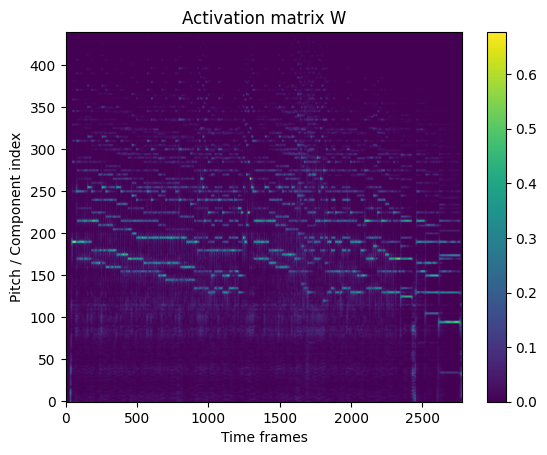

In [3]:
from scipy.io import wavfile
import librosa
import numpy as np

file_name_string_audio = "Prelude-in-E-Minor-Nr-4.wav"
f_s, x = wavfile.read(file_name_string_audio)
if(x.dtype==np.int32):
  x = x / (2**31)
elif(x.dtype==np.int16):
  x = x / (2**15)
else:
  raise ValueError(f"Unsupported sample type: {x.dtype}")
spectrogram = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K+L, hop_length=HOP, sparsity=0.05))
#spectrogram, P = librosa.decompose.hpss(spectrogram, margin=1.0)
#spectrogram_1 = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K, hop_length=HOP))
onsets = librosa.onset.onset_detect(y=x, sr=f_s, hop_length=HOP,units='frames')
def norm_log(H, gamma=5):
    return np.log1p(gamma * H)
spectrogram = norm_log(spectrogram, g)
spectrogram = librosa.util.normalize(spectrogram, norm = 2, axis = 0, threshold = 0.05)

import matplotlib.pyplot as plt
plt.figure()
plt.imshow(spectrogram, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

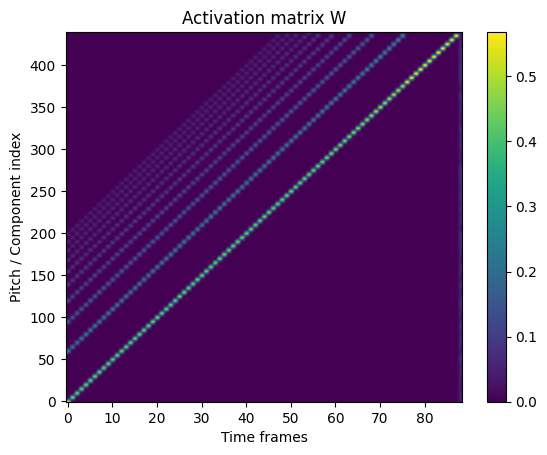

In [4]:
def build_W0(
    sr,
    bins_per_octave,
    n_bins,
    fmin,
    n_harmonics=10,
    decay=1.0,
    sigma=1.5,
    inharmonicity=0.0,
):
    # CQT frequency grid: must match your spectrogram
    freqs = librosa.cqt_frequencies(
        n_bins=n_bins,
        fmin=fmin,
        bins_per_octave=bins_per_octave,
    )

    # Log-frequency coordinates corresponding to CQT bins
    log_freqs = np.log2(freqs)
    k = np.arange(n_bins, dtype=float)

    # Piano pitches: MIDI 21 (A0) through MIDI 108 (C8)
    midi_notes = np.arange(21, 109)

    W0 = np.zeros((n_bins, len(midi_notes)), dtype=float)

    f_max = min(freqs[-1], sr / 2.0)

    for i, m in enumerate(midi_notes):
        f0 = librosa.midi_to_hz(m)
        template = np.zeros(n_bins, dtype=float)

        for h in range(1, n_harmonics + 1):

            # Harmonic frequency, optionally including piano
            # string inharmonicity.
            fh = h * f0 * np.sqrt(
                (1.0 + inharmonicity * h**2)
                / (1.0 + inharmonicity)
            )

            # CRITICAL FIX:
            # Never map out-of-range harmonics onto the
            # first or last CQT bin.
            if fh >= f_max:
                break

            if fh < freqs[0]:
                continue

            # Fractional bin coordinate in log-frequency space
            center = np.interp(
                np.log2(fh),
                log_freqs,
                k,
            )

            # Gaussian harmonic peak
            peak = np.exp(
                -0.5 * ((k - center) / sigma) ** 2
            )

            template += peak / (h ** decay)

        # L2 normalization
        norm = np.linalg.norm(template)
        if norm > 1e-10:
            template /= norm

        W0[:, i] = template

    return W0

def build_noise_basis(n_bins, n_components=2):
    Wn = np.zeros((n_bins, n_components))

    for i in range(n_components):
        # random smooth noise shape
        x = np.random.rand(n_bins)
        x = np.convolve(x, np.hanning(15), mode='same')
        x /= np.linalg.norm(x) + 1e-10
        Wn[:, i] = x

    return Wn
W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K+L, fmin=librosa.note_to_hz('A0'), sigma=1.75)
#W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K, fmin=librosa.note_to_hz('A0'), sigma=2.0)
Wn = build_noise_basis(88*K+L, 1)
W_0 = np.concatenate([W_0, Wn], axis=1)
#W_0 = W_norm(W_0)
#print(W_0.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W_0, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [5]:
W, H, history = hnma(
    spectrogram,
    W_init=W_0,
    n_components=88+1,
    lambda_alpha=1e-3,
    #beta_mode='temporal_smoothness',
    #lambda_beta=1e-6,
    #lambda_shift=0.1,
    #shift_bins=33,
    #lambda_volume=1e-3,
    #volume_delta=1e-6,
    #volume_mode = "max",
    bins_per_octave=12*K,
    max_iter=500,
    tol=1e-5,
    random_state=42,
)

V_hat = W @ H

print("W:", W.shape)
print("H:", H.shape)


W: (440, 89)
H: (89, 2781)


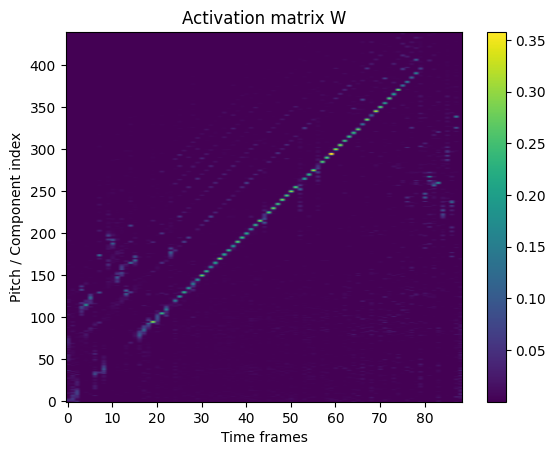

In [6]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

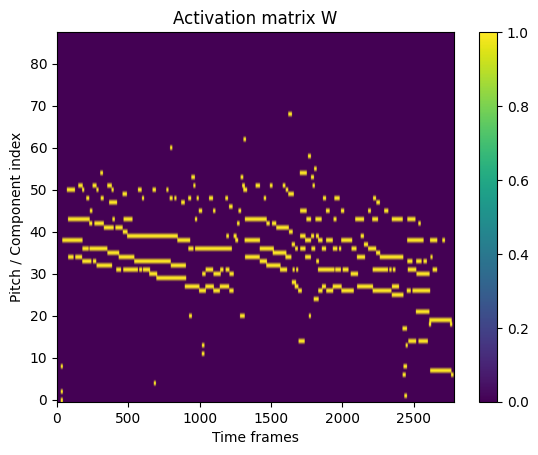

In [7]:
import scipy
from scipy.ndimage import label
def med_filter(X, sz=5):
  X_r = np.zeros(X.shape)
  for i in range(X.shape[0]):
    X_r[i,:] = scipy.ndimage.median_filter(X[i,:], size=sz, cval=0, mode='constant')
  return X_r

def enforce_min_duration(B, min_len=10):
    for q in range(B.shape[0]):
        labels, n = label(B[q])
        for i in range(1, n+1):
            if np.sum(labels == i) < min_len:
                B[q][labels == i] = 0
    return B

H1 = med_filter(H,sz=9)
#H1 = med_filter(H)
H2 = np.zeros_like(H1)
idx = np.argpartition(H1, -10, axis=0)[-10:, :]
H2[idx, np.arange(H1.shape[1])] = H1[idx, np.arange(H1.shape[1])]
H3 = med_filter(H2,sz=7)
t = H3.max() * 0.125
H4 = (H3 > t).astype(int)
H5 = enforce_min_duration(H4,min_len=15)[0:88,:]
#z = analyse_spectrogram(spectrogram, onsets)
#H6 = clear_H(H5,onsets,z)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(H5, aspect='auto', origin='lower')
'''for idx in onsets:
    plt.axvline(x=idx, color='red', linewidth=0.8, alpha=0.8)'''
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [8]:
pip install pretty_midi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 23.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pretty_midi]


In [9]:
import numpy as np
import pretty_midi

def midi_to_binary_matrix(
    midi_input,
    dt=0.02,                     # time quantum in seconds
    pitch_range=(21, 108),  # A0–C8 by default
    min_overlap=0.5         # fraction of frame that must be covered
):
    """
    Convert MIDI to binary (88 x T) note activation matrix using fixed time grid.

    A note is active in a frame if it overlaps the frame
    by at least min_overlap * dt.
    """

    if dt <= 0:
        raise ValueError("dt must be positive (seconds)")

    # Load MIDI
    if isinstance(midi_input, pretty_midi.PrettyMIDI):
        pm = midi_input
    else:
        pm = pretty_midi.PrettyMIDI(midi_input)

    # Time axis
    total_time = pm.get_end_time()
    T = int(np.ceil(total_time / dt))
    frame_times = np.arange(T) * dt

    n_pitches = pitch_range[1] - pitch_range[0] + 1
    B = np.zeros((n_pitches, T), dtype=np.uint8)

    # Process notes
    for instrument in pm.instruments:
        if instrument.is_drum:
            continue

        for note in instrument.notes:
            if not (pitch_range[0] <= note.pitch <= pitch_range[1]):
                continue

            p = note.pitch - pitch_range[0]

            start_frame = int(np.floor(note.start / dt))
            end_frame   = int(np.ceil(note.end   / dt))

            for t in range(start_frame, min(end_frame, T)):
                frame_start = t * dt
                frame_end   = frame_start + dt

                overlap = max(
                    0.0,
                    min(note.end, frame_end) - max(note.start, frame_start)
                )

                if overlap >= min_overlap * dt:
                    B[p, t] = 1

    return B, frame_times

(88, 2757) (89, 2781)


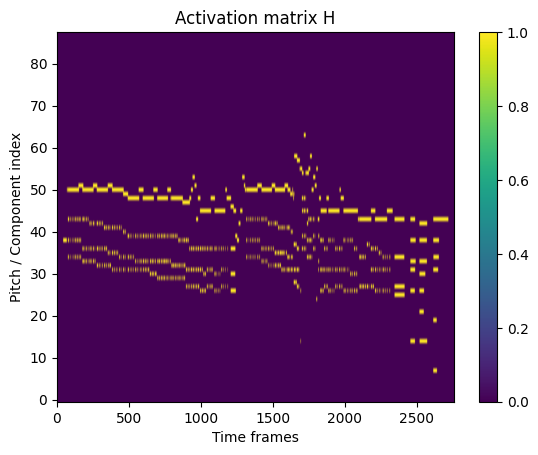

In [10]:
# 20 ms frames (matches typical STFT hop ~512 @ 44.1kHz)
dt = HOP / f_s
B, times = midi_to_binary_matrix(
    "Prelude-in-E-Minor-Nr-4.mid",
    dt=dt
)
print(B.shape,H4.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(B, aspect='auto', origin='lower')
#for idx in onsets:
#    plt.axvline(x=idx, color='red', linewidth=0.8, alpha=0.8)
plt.colorbar()
plt.title("Activation matrix H")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [11]:
def evaluate_results(H_et,H):
  #H_et - reference transcription of the piece
  #H - estimated transcription of the piece
  assert H_et.shape == H.shape
  P = 0
  R = 0
  F1 = 0
  TP = 0
  FP = 0
  FN = 0
  for i in range(H_et.shape[1]):
    TP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 1)
    FP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 0 and p == 1)
    FN += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 0)
  P = TP / (TP + FP)
  R = TP / (TP + FN)
  F1 = 2 * P * R / (P + R)
  return (P,R,F1)

In [12]:
print(H5.shape)

(88, 2781)


In [13]:
print(evaluate_results(H5[:,:B.shape[1]],B))

(0.6958990536277603, 0.4535828107330112, 0.5492002240617414)


In [14]:
pip install hmmlearn

In [15]:
import numpy as np
from hmmlearn.hmm import GaussianHMM


class BinaryGaussianHMMTrainer:

    def __init__(
        self,
        transition_smoothing=1.0,
        start_smoothing=1.0,
        variance_floor=1e-5
    ):

        if transition_smoothing < 0 or start_smoothing < 0:
            raise ValueError("Smoothing parameters must be nonnegative.")

        if variance_floor <= 0:
            raise ValueError("variance_floor must be positive.")

        self.transition_smoothing = transition_smoothing
        self.start_smoothing = start_smoothing
        self.variance_floor = variance_floor

        # HMM initial-state counts
        self.start_counts = np.zeros(2, dtype=np.float64)

        # HMM transition counts
        self.transition_counts = np.zeros((2, 2), dtype=np.float64)

        # Number of observations belonging to each state
        self.state_counts = np.zeros(2, dtype=np.int64)

        # Running Gaussian statistics
        self.means = None
        self.M2 = None

        # Feature dimensionality
        self.n_features = None

        # Number of processed recordings
        self.n_sequences = 0

    # ==================================================
    # Add a new recording to the training dataset
    # ==================================================

    def update(self, X, y, lengths=None):

        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y).ravel()

        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")

        if len(X) != len(y):
            raise ValueError("X and y must have the same number of frames.")

        if len(y) == 0:
            raise ValueError("Empty sequence.")

        if not np.all(np.isfinite(X)):
            raise ValueError("X contains NaN or infinite values.")

        if not np.all(np.isin(y, [0, 1])):
            raise ValueError("y must contain only 0 and 1.")

        y = y.astype(int)

        T, n_features = X.shape

        # ----------------------------------------------
        # Sequence lengths
        # ----------------------------------------------

        if lengths is None:
            lengths = np.array([T], dtype=int)
        else:
            raw_lengths = np.asarray(lengths)

            if (
                raw_lengths.ndim != 1
                or not np.all(np.isfinite(raw_lengths))
                or np.any(raw_lengths != np.floor(raw_lengths))
            ):
                raise ValueError("Invalid sequence lengths.")

            lengths = raw_lengths.astype(int)

        if (
            len(lengths) == 0
            or np.any(lengths <= 0)
            or np.sum(lengths) != T
        ):
            raise ValueError("Invalid sequence lengths.")

        # ----------------------------------------------
        # Initialize feature statistics
        # ----------------------------------------------

        if self.n_features is None:

            self.n_features = n_features

            self.means = np.zeros(
                (2, n_features),
                dtype=np.float64
            )

            self.M2 = np.zeros(
                (2, n_features),
                dtype=np.float64
            )

        elif self.n_features != n_features:

            raise ValueError(
                f"Expected {self.n_features} features, "
                f"got {n_features}."
            )

        # ----------------------------------------------
        # 1. Initial-state and transition counts
        # ----------------------------------------------

        offset = 0

        for L in lengths:

            ys = y[offset:offset + L]

            # Initial state
            self.start_counts[ys[0]] += 1

            # Transitions
            if L > 1:

                np.add.at(
                    self.transition_counts,
                    (ys[:-1], ys[1:]),
                    1
                )

            offset += L

        # ----------------------------------------------
        # 2. Update Gaussian emission statistics
        # ----------------------------------------------

        for state in (0, 1):

            X_state = X[y == state]

            batch_n = len(X_state)

            if batch_n == 0:
                continue

            # Statistics of the current recording
            batch_mean = np.mean(X_state, axis=0)

            centered = X_state - batch_mean

            batch_M2 = np.sum(
                centered ** 2,
                axis=0
            )

            # Statistics accumulated from previous recordings
            old_n = self.state_counts[state]

            new_n = old_n + batch_n

            if old_n == 0:

                self.means[state] = batch_mean
                self.M2[state] = batch_M2

            else:

                delta = batch_mean - self.means[state]

                self.means[state] += (
                    delta * batch_n / new_n
                )

                self.M2[state] += (
                    batch_M2
                    + delta ** 2 * old_n * batch_n / new_n
                )

            self.state_counts[state] = new_n

        self.n_sequences += len(lengths)

        return self

    # ==================================================
    # Construct an HMM using accumulated statistics
    # ==================================================

    def get_model(self):

        if self.n_features is None:
            raise ValueError("No training data has been added.")

        if np.any(self.state_counts == 0):

            raise ValueError(
                "Both states must occur in the training dataset. "
                f"State counts: {self.state_counts}"
            )

        # ----------------------------------------------
        # Initial probabilities
        # ----------------------------------------------

        startprob = (
            self.start_counts + self.start_smoothing
        )

        if startprob.sum() == 0:
            raise ValueError("No initial-state observations.")

        startprob /= startprob.sum()

        # ----------------------------------------------
        # Transition probabilities
        # ----------------------------------------------

        transmat = (
            self.transition_counts + self.transition_smoothing
        )

        row_sums = transmat.sum(axis=1, keepdims=True)

        if np.any(row_sums == 0):
            raise ValueError(
                "A state has no outgoing transitions. "
                "Increase transition_smoothing."
            )

        transmat /= row_sums

        # ----------------------------------------------
        # Gaussian means and diagonal covariances
        # ----------------------------------------------

        means = self.means.copy()

        # Maximum-likelihood variance estimates
        covars = (
            self.M2 /
            self.state_counts[:, None]
        )

        covars = np.maximum(
            covars,
            self.variance_floor
        )

        # ----------------------------------------------
        # Construct GaussianHMM
        # ----------------------------------------------

        model = GaussianHMM(
            n_components=2,
            covariance_type="diag",
            algorithm="viterbi",
            init_params="",
            params=""
        )

        model.n_features = self.n_features

        model.startprob_ = startprob
        model.transmat_ = transmat
        model.means_ = means
        model.covars_ = covars

        return model

In [ ]:
print(y_pred)

In [ ]:
import matplotlib.pyplot as plt

plt.plot(y_pred)
plt.xlabel("Index")
plt.ylabel("Value")
plt.grid()
plt.show()

In [17]:
from pathlib import Path
def get_files(extension):
    return [str(file) for file in Path.cwd().rglob("*."+extension)]
l = get_files("")
print(l)

[]


In [18]:
import soundfile as sf
import numpy as np

def read_wav_as_float(file_path):

    # Read audio directly as float32
    x, sr = sf.read(
        file_path,
        dtype="float32",
        always_2d=True
    )

    n_frames, n_channels = x.shape

    print(
        f"Channels: {n_channels}, "
        f"Sample Rate: {sr}, "
        f"Frames: {n_frames}"
    )

    # Convert stereo/multichannel audio to mono
    x = np.mean(x, axis=1, dtype=np.float32)

    return sr, np.ascontiguousarray(x)

In [19]:
def midi_to_cqt_labels(
    midi_input,
    n_frames,
    sr,
    hop_length,
    pitch_range=(21, 108)
):
    """
    Generate MIDI ground-truth labels at CQT frame centers.

    Returns
    -------
    B : ndarray, shape (n_pitches, n_frames)
        Binary piano roll.
    """

    if isinstance(midi_input, str):
        midi = pretty_midi.PrettyMIDI(midi_input)
    else:
        midi = midi_input

    dt = hop_length / sr

    # CQT frame center timestamps
    times = np.arange(n_frames) * dt

    pitches = np.arange(
        pitch_range[0],
        pitch_range[1] + 1
    )

    B = np.zeros(
        (len(pitches), n_frames),
        dtype=np.uint8
    )

    for instrument in midi.instruments:

        for note in instrument.notes:

            if note.pitch not in pitches:
                continue

            pitch_idx = note.pitch - pitch_range[0]

            active = (
                (times >= note.start) &
                (times < note.end)
            )

            B[pitch_idx, active] = 1

    return B

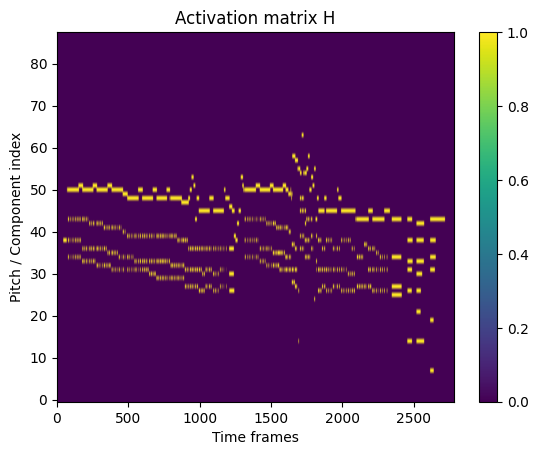

In [21]:
M = midi_to_cqt_labels("/content/Prelude-in-E-Minor-Nr-4.mid", 2781, 44100,2048)
import matplotlib.pyplot as plt

plt.imshow(M, aspect='auto', origin='lower')
#for idx in onsets:
#    plt.axvline(x=idx, color='red', linewidth=0.8, alpha=0.8)
plt.colorbar()
plt.title("Activation matrix H")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [22]:
def list_spectrograms():
  l = get_files("wav")
  r = get_files("mid")
  for m in l.copy():
    if(not m[:-3]+"mid" in r):
      l.remove(m)
  trainers = [BinaryGaussianHMMTrainer() for _ in range(88)]
  for file_name_string_audio in l:
    f_s, x = read_wav_as_float(file_name_string_audio)
    W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K+L, fmin=librosa.note_to_hz('A0'), sigma=1.75)
    Wn = build_noise_basis(88*K+L, 1)
    W_0 = np.concatenate([W_0, Wn], axis=1)
    print(file_name_string_audio, x.shape, x.dtype)
    spectrogram = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K+L, hop_length=HOP, sparsity=0.05))
    #spectrogram = librosa.decompose.hpss(spectrogram)[0]
    spectrogram = norm_log(spectrogram, g)
    spectrogram = librosa.util.normalize(spectrogram, norm = 2, axis = 0, threshold = 0.05)
    W, H, history = hnma(
        spectrogram,
        W_init=W_0,
        n_components=88+1,
        lambda_alpha=1e-3,
        bins_per_octave=12*K,
        max_iter=500,
        tol=1e-5,
        random_state=42,
    )
    '''dt = HOP / f_s
    B, times = midi_to_binary_matrix(
        file_name_string_audio[:-3]+"mid",
        dt=dt
    )'''
    B = midi_to_cqt_labels(
      file_name_string_audio[:-3]+"mid",
      n_frames=H.shape[1],
      sr=f_s,
      hop_length=HOP
    )
    print(H.shape[1],B.shape[1])
    #print(file_name_string_audio)
    #s.append((H[:88,:B.shape[1]],B))
    #for i in range(len(H_files)):
    '''s = min(B.shape[1],H.shape[1])
    print(H.shape)
    print("shapes:",H[:88,:s].T.shape, B[:,:s].shape)
    for pitch in range(88):
      trainers[pitch].update(H[:88,:B.shape[1]].T,B[pitch, :s])'''
    for pitch in range(88):
      trainers[pitch].update(H[pitch-1:pitch+2,:].T,B[pitch, :])
    del x, W_0, Wn, spectrogram
    del W, H, history
  return trainers

In [23]:
res = list_spectrograms()

Channels: 1, Sample Rate: 44100, Frames: 5695232
/content/Prelude-in-E-Minor-Nr-4.wav (5695232,) float32
2781 2781
Channels: 2, Sample Rate: 44100, Frames: 3037440
/content/WAVMIDIs/chpn-p19.wav (3037440,) float32
1484 1484
Channels: 2, Sample Rate: 44100, Frames: 15656192
/content/WAVMIDIs/chpn_op53.wav (15656192,) float32
7645 7645
Channels: 2, Sample Rate: 44100, Frames: 2088192
/content/WAVMIDIs/chpn-p18.wav (2088192,) float32
1020 1020
Channels: 2, Sample Rate: 44100, Frames: 2939648
/content/WAVMIDIs/chpn-p16.wav (2939648,) float32
1436 1436
Channels: 2, Sample Rate: 44100, Frames: 4537344
/content/WAVMIDIs/chpn-p4.wav (4537344,) float32
2216 2216
Channels: 2, Sample Rate: 44100, Frames: 6084096
/content/WAVMIDIs/chpn_op7_1.wav (6084096,) float32
2971 2971
Channels: 2, Sample Rate: 44100, Frames: 22882816
/content/WAVMIDIs/chp_op31.wav (22882816,) float32
11174 11174
Channels: 2, Sample Rate: 44100, Frames: 1567488
/content/WAVMIDIs/chpn-p5.wav (1567488,) float32
766 766
Channels

In [ ]:
res[29].get_model()

In [ ]:
models = [
    res[i].get_model()
    for i in range(20,len(res)-8)
]

In [ ]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(H, aspect='auto', origin='lower')
'''for idx in onsets:
    plt.axvline(x=idx, color='red', linewidth=0.8, alpha=0.8)'''
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [ ]:
print(np.sum(W[:,46]))

In [ ]:
X = np.zeros((88,H.shape[1]))
print(X.shape)
print(H.shape)

In [56]:
H_u = norm_log(H * 100, g)
H_u = librosa.util.normalize(H, norm = 2, axis = 0, threshold = 0.05)
#H_u = librosa.decompose.hpss(H_u)[0]
pitch_indices = range(20, len(res)-8)

models = [
    res[i].get_model()
    for i in pitch_indices
]

X_obs = H_u[:88, :].T

piano_roll = np.zeros(
    (88, H_u.shape[1]),
    dtype=np.uint8
)

for pitch in pitch_indices:

    model_idx = pitch - 20

    # Five neighboring pitch activations
    X_pitch = X_obs[:, pitch-1:pitch+2]

    piano_roll[pitch, :] = models[model_idx].predict(X_pitch)

In [ ]:
def clear_piano_roll(W, H):


In [ ]:
print(W[196,39])

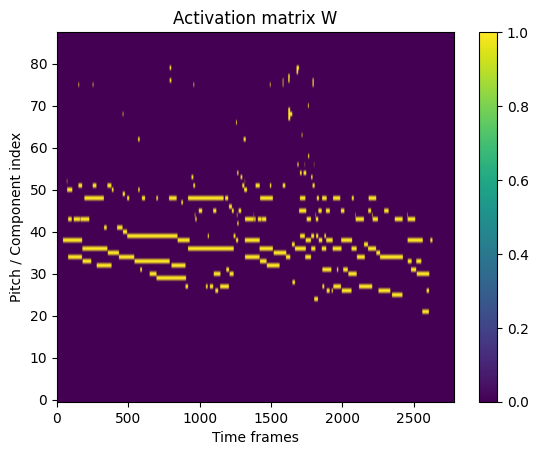

In [57]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(piano_roll, aspect='auto', origin='lower')
'''for idx in onsets:
    plt.axvline(x=idx, color='red', linewidth=0.8, alpha=0.8)'''
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [59]:
print(evaluate_results(piano_roll[:,:B.shape[1]],B))

(0.5162460567823344, 0.460337552742616, 0.4866914498141264)


In [ ]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [ ]:
for pitch in [20, 39, 60, 80]:
    model = res[pitch].get_model()

    print(f"\nPitch index: {pitch}")
    print("Means:\n", model.means_)
    print("Variances:\n", model.covars_)
    print("Transitions:\n", model.transmat_)

In [ ]:
pitch = 39

model = res[pitch].get_model()

print("State transition matrix:")
print(model.transmat_)

print("\nInitial probabilities:")
print(model.startprob_)

print("\nMean activation vectors:")
print(model.means_)

In [ ]:
print("Pitch activation when inactive:",
      model.means_[0, pitch])

print("Pitch activation when active:",
      model.means_[1, pitch])

In [ ]:
import matplotlib.pyplot as plt

pitch = 39

X_test = H[pitch-2:pitch+3, :].T

y_pred = model.predict(X_test)

fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 7),
    sharex=True
)

axes[0].plot(B[pitch, :len(y_pred)])
axes[0].set_title("Ground truth")

axes[1].plot(H[pitch, :len(y_pred)])
axes[1].set_title("HNMA activation")

axes[2].plot(y_pred)
axes[2].set_title("HMM prediction")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# During training:
X_train = scaler.fit_transform(H)

# During inference:
X_test = scaler.transform(H)

In [ ]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(X_test, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [ ]:
def estimate_alignment_lag(
    activation,
    labels,
    max_lag=30
):
    activation = np.asarray(activation, dtype=float)
    labels = np.asarray(labels, dtype=float)

    n = min(len(activation), len(labels))

    activation = activation[:n]
    labels = labels[:n]

    # Normalize
    activation = (
        activation - activation.mean()
    ) / (activation.std() + 1e-10)

    labels = (
        labels - labels.mean()
    ) / (labels.std() + 1e-10)

    lags = np.arange(-max_lag, max_lag + 1)
    correlations = []

    for lag in lags:

        if lag > 0:
            a = activation[lag:]
            b = labels[:-lag]

        elif lag < 0:
            a = activation[:lag]
            b = labels[-lag:]

        else:
            a = activation
            b = labels

        correlations.append(
            np.mean(a * b)
        )

    best_idx = np.argmax(correlations)

    return lags[best_idx], correlations[best_idx]

In [ ]:
pitch = 39

lag, corr = estimate_alignment_lag(
    H[pitch],
    B[pitch],
    max_lag=30
)

print("Estimated lag:", lag, "frames")
print("Correlation:", corr)

print(
    "Estimated time offset:",
    lag * HOP / 22050,
    "seconds"
)